# Projeto 2

Charlie Alvez Cruz Brambilha- RA 198174 <br>
Letícia Palomero Rodrigues - RA 239038 <br>
Pedro Teruo Hidaka Luiz -RA 239643

In [63]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat


## Parte 1 - Análise de Componentes Principais

### 1.a

In [64]:
from numpy.linalg import svd

In [65]:
# Carregando os dados
dado1 = loadmat("dados/dado1.mat") # imagens 32 x 32
X1 = dado1["X"]                    # 5000 x 1024

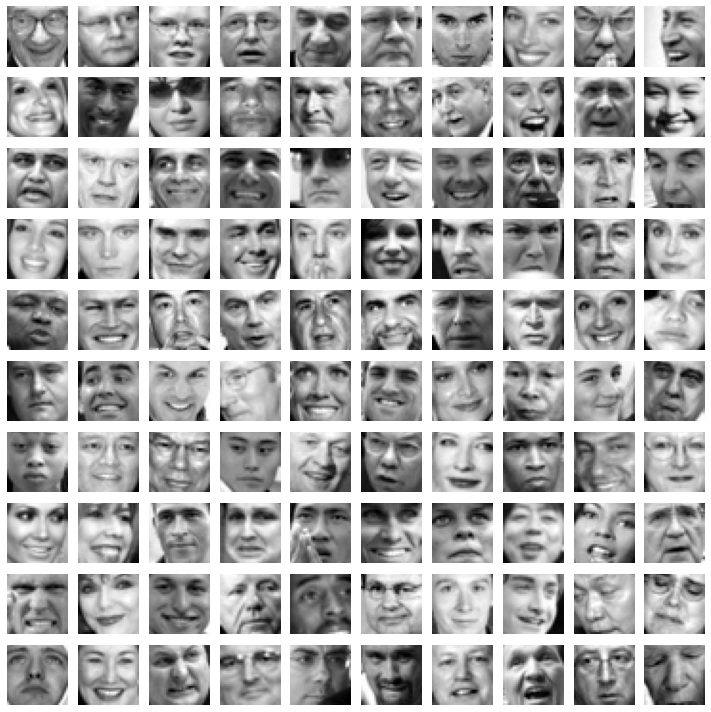

In [66]:
# Mostrando as 100 primeiras imagens
figura, eixos = plt.subplots(10, 10, figsize=(10, 10)) # criando a grade 10 x 10

# rearranjando as linhas em matrizes 32 x 32
for i, eixo in enumerate(eixos.flat):
    imagem = X1[i, :].reshape(32, 32).T
    eixo.imshow(imagem, cmap='gray')
    eixo.axis('off')

plt.tight_layout()
plt.show()

In [67]:
# Normalizando os atributos de entrada
def normalizarAtributos(X):
    mu = np.mean(X, axis=0)   # vetor com a média dos atributos
    s = np.std(X, axis=0)     # vetor com o desvio padrão dos atributos
    X_normalizado = (X - mu) / s # vetor com os atributos normalizados
    
    return X_normalizado, mu, s

In [68]:
# Fazendo a decomposição em valores singulares (SVD)
def calcularSVD(X):
    m = X.shape[0]
    Sigma = 1/m * X.T @ X # matriz de covariância
    U, S, V = svd(Sigma)  # decomposição em valores singulares

    return U,S,V

In [69]:
# Projetando os dados X sobre U
def projetarDados(X, U, K):
    m = X.shape[0]
    U_reduzido = U[:, :K] # K primeiras colunas de U
    Z = np.zeros((m, K))
    
    Z = X @ U[:, :K] # vetor z com dimensão reduzida (projeção)
    
    return Z

In [72]:
# Obtendo a aproximação os dados projetados
def reconstruirDados(Z, U, K):
    m,n = Z.shape[0],U.shape[1]
    X_aproximado = np.zeros((m, n))
    U_reduzido = U[:, :K] # K primeiras colunas de U
    
    X_aproximado = Z @ U[:, :K].T # aproximação de X resultante da redução de dimensão
        
    return X_aproximado

In [ ]:
# Obtendo U e S por SVD
X1_normalizado, mu, s = normalizarAtributos(X1)
U, S = calcularSVD(X1_normalizado)[:2]
# U (1024 x 1024) é a matriz dos autovetores
# S (1024 x 1) é uma matriz diagonal com os autovalores da covariância

k = 100 # dimensão reduzida
Z = projetarDados(X1_normalizado, U, k) # 5000 x 100

X1_aproximado = reconstruirDados(Z, U, k) # 5000 x 1024

### 1.b

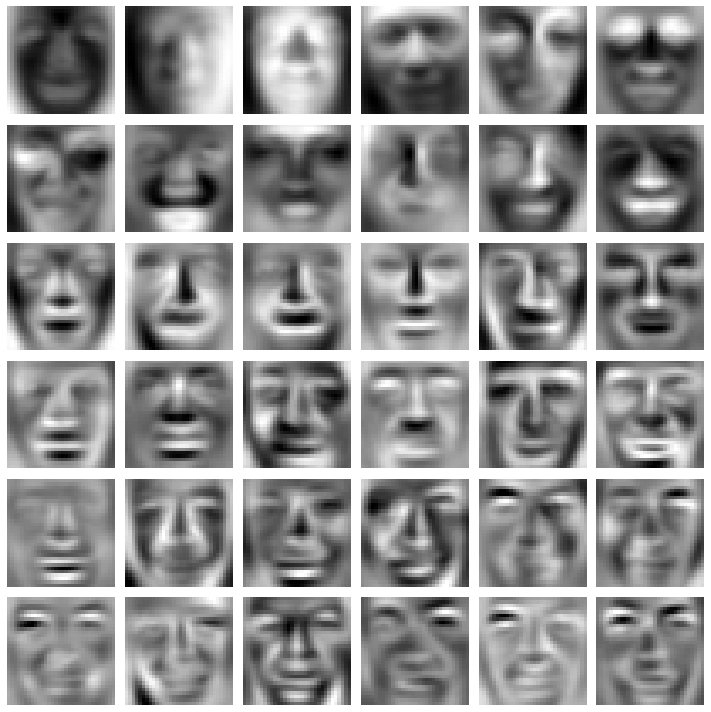

In [74]:
# Mostrando as 36 primeiras eigenfaces
figura, eixos = plt.subplots(6, 6, figsize=(10, 10)) # criando a grade 6 x 6

# Rearranjando as linhas em matrizes 32 x 32
for i, eixo in enumerate(eixos.flat):
    imagem = U[:, i].reshape(32, 32).T # usando as colunas ao invés das linhas
    eixo.imshow(imagem, cmap='gray')
    eixo.axis('off')

plt.tight_layout()
plt.show()

### 1.c

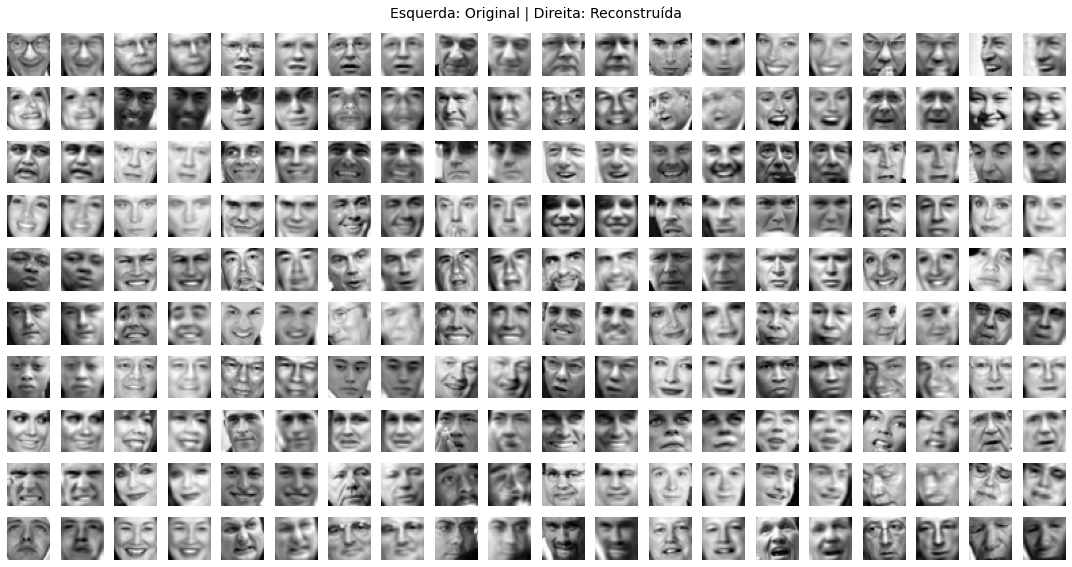

In [75]:
# Mostrando as 100 primeiras imagens originais e aproximadas por PCA
X1_aproximado_desnormalizado = (X1_aproximado * s) + mu # X_aproximado foi calculado usando X normalizado, então desnormalizamos ele para as cores estarem de acordo com as dos dados originais

figura, eixos = plt.subplots(10, 20, figsize=(15, 8)) # criando a grade 10 x 20

# As imagens das faces serão exibidas com as originais seguidas das aproximadas
for i in range(100):
    linha = i // 10
    coluna_original = (i % 10) * 2
    coluna_aproximada = coluna_original + 1

    # Faces dos dados
    imagem_original = X1[i, :].reshape(32, 32).T # rearranjando as linhas em matrizes 32 x 32
    eixos[linha, coluna_original].imshow(imagem_original, cmap='gray')
    eixos[linha, coluna_original].axis('off')

    # Faces dos dados aproximados
    imagem_aproximada = X1_aproximado_desnormalizado[i, :].reshape(32, 32).T # rearranjando as linhas em matrizes 32 x 32
    eixos[linha, coluna_aproximada].imshow(imagem_aproximada, cmap='gray')
    eixos[linha, coluna_aproximada].axis('off')

plt.suptitle("Esquerda: Original | Direita: Reconstruída", fontsize=14)
plt.tight_layout()
plt.show()

## Parte 2 - Sistemas de Recomendação

### 2.a

In [76]:
from scipy.optimize import minimize

In [77]:
np.random.seed(0)

In [ ]:
# Carregando os dados
dado2 = loadmat("dados/dado2.mat")
Y = dado2["Y"] # 1682 x 943
R = dado2["R"] # 1682 x 943.split(" ", 1)[1]

In [ ]:
# Função de Custo
def computarCusto(Y, R, parametros, numero_usuarios, numero_filmes, numero_atributos, Lambda):
    X = parametros[:numero_filmes * numero_atributos].reshape(numero_filmes, numero_atributos)
    Theta = parametros[numero_filmes * numero_atributos:].reshape(numero_usuarios, numero_atributos)    

    # Forward Propagation
    resultado = X @ Theta.T
    erro = resultado - Y

    X_regularizada = Lambda / 2 * (np.sum(X**2))             # X regularizada
    Theta_regularizada = Lambda / 2 * (np.sum(Theta**2))     # Theta regularizada

    J = 1 / 2 * np.sum((erro**2) * R)                        # Função de custo
    J_regularizada = J + X_regularizada + Theta_regularizada # Função de custo regularizada

    X_gradiente = erro * R @ Theta
    Theta_gradiente = (erro * R).T @ X
    gradiente = np.append(X_gradiente.flatten(), Theta_gradiente.flatten())

    # Regularizando o gradiente
    X_gradiente_regularizado = X_gradiente + Lambda * X
    Theta_gradiente_regularizado = Theta_gradiente + Lambda * Theta
    gradiente_regularizado = np.append(X_gradiente_regularizado.flatten(), Theta_gradiente_regularizado.flatten())

    return J, gradiente, J_regularizada, gradiente_regularizado.split(" ", 1)[1]

In [80]:
# Função para inicializar as matrizes com pesos aleatórios
def inicializarPesosAleatorios(tamanho_camada_entrando, tamanho_camada_saindo):
    W = 0.1 * np.random.randn(tamanho_camada_entrando, tamanho_camada_saindo)
    return W

In [81]:
# Função objetivo a ser minimizada (usada como parâmetro no minimize)
def fun_jac(parametros, Y, R, nu, nf, na, Lambda):
    _, _, J, g = computarCusto(Y, R, parametros, nu, nf, na, Lambda)
    return J, g

In [ ]:
# Método para calcular Y normalizado
def normalizarNotas(Y, R):
    m, n = Y.shape[0], Y.shape[1]
    Y_medias = np.zeros((m, 1))
    Y_normalizado = np.zeros((m, n))
    
    for i in range(m):
        # Calculando a média para os filmes que foram avaliados (Ri diferente de 0)
        Y_medias[i] = np.sum(Y[i, :]) / np.count_nonzero(R[i, :])

        # Subtraindo a média dos yi dos yi para obter Y normalizado.split(" ", 1)[1]

In [83]:
# Parâmetros
numero_filmes, numero_usuarios = Y.shape
numero_atributos = 100
Lambda = 0 # função de custo sem regularização
iteracoes = 500 # número máximo de iterações do gradiente conjugado

# Inicialização aleatória
X2 = inicializarPesosAleatorios(numero_filmes, numero_atributos)
Theta = inicializarPesosAleatorios(numero_usuarios, numero_atributos)
parametros_iniciais = np.append(X2.flatten(), Theta.flatten())


In [115]:
# Fazendo o treinamento e a predição

Y_normalizado, Y_medias = normalizarNotas(Y, R)

# Usando o scipy.optimize.minimize para obter X e Theta por gradiente conjugado
resultado_minimize = minimize(fun=fun_jac, x0=parametros_iniciais, args=(Y_normalizado, R, numero_usuarios, numero_filmes, numero_atributos, Lambda), jac=True, method='CG', options={'maxiter': iteracoes, 'disp': True})

# Separando X e Theta
X2 = resultado_minimize.x[:numero_filmes * numero_atributos].reshape(numero_filmes, numero_atributos)
Theta = resultado_minimize.x[numero_filmes * numero_atributos:].reshape(numero_usuarios, numero_atributos)

# Obtendo as previsões das notas dos filmes a partir de X e Theta calculados com minimize
resultados = X2 @ Theta.T # Fazendo a previsão
resultados = resultados + Y_medias # Revertendo a normalização

         Current function value: 0.000002
         Iterations: 500
         Function evaluations: 770
         Gradient evaluations: 770


In [ ]:
# Algumas informaçẽos sobre os dados previstos - reparar que eles não estão entre 1 e 5
print(resultados.max())
print(resultados.min())
print(resultados.mean())

11.187270958740218
-3.751879559083613
3.0665573261110177


### 2.b

In [117]:
import pandas as pd

In [118]:
# Carregando os dados
lista_filmes = open("dados/dado3.txt","r", encoding='iso8859-1').read().split("\n")[:-1] # 1682
lista_filmes = [filme.split(" ", 1)[1] for filme in lista_filmes]

In [119]:
# Calculando a média das notas dos filmes
notas_medias = resultados.mean(axis=1)

# Número de usuários que avaliaram cada filme
numero_avaliacoes = R.sum(axis=1) # 1682

# Juntando as médias com os nomes dos filmes e o número de avaliações
df_filmes = pd.DataFrame({"Filme": lista_filmes, "Nota Média": notas_medias, "Nº Avaliações": numero_avaliacoes})

# Exibindo os filmes com a maior nota média
numero_mostrar = 10
print("Filmes com notas médias mais altas:")
print(df_filmes.sort_values("Nota Média", ascending=False).head(numero_mostrar))

Filmes com notas médias mais altas:
                                                  Filme  Nota Média  \
1292                                    Star Kid (1997)    5.010348   
1598                      Someone Else's America (1995)    5.008662   
1188                                 Prefontaine (1997)    5.008188   
1200         Marlene Dietrich: Shadow and Light (1996)     5.004459   
1466               Saint of Fort Washington, The (1993)    5.004431   
1499                          Santa with Muscles (1996)    5.003064   
1535                               Aiqing wansui (1994)    4.999046   
813                       Great Day in Harlem, A (1994)    4.996186   
1652  Entertaining Angels: The Dorothy Day Story (1996)    4.985928   
1121                     They Made Me a Criminal (1939)    4.983872   

      Nº Avaliações  
1292              3  
1598              1  
1188              3  
1200              1  
1466              2  
1499              2  
1535              1  
813   

In [120]:
# Média e mediana do número de avaliações dos filmes para comparar com a tabela das maiores notas
print("Média:  ", numero_avaliacoes.mean())
print("Mediana:", np.median(numero_avaliacoes))

Média:   59.45303210463734
Mediana: 27.0


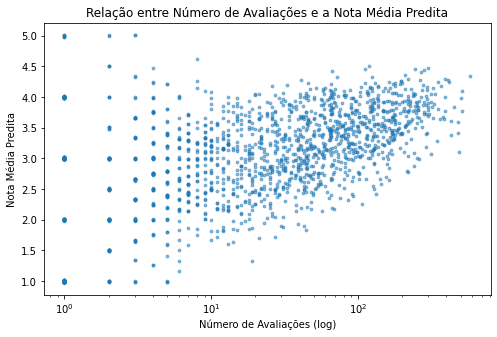

In [121]:
plt.figure(figsize=(8, 5))
plt.scatter(numero_avaliacoes, notas_medias, s=8, alpha=0.5)
plt.xscale("log")
plt.xlabel("Número de Avaliações (log)")
plt.ylabel("Nota Média Predita")
plt.title("Relação entre Número de Avaliações e a Nota Média Predita")
plt.show()